# Lab 10: How to draw, pause and resume an agent with LangGraph

**Notebook 2 of 2: LangGraph at the Chinook desk**

## Goal

Build the agent of the Chinook support desk as a graph that we write ourselves, then use what a hand-written graph
gives us. First, a step of our own between the model and its tools: a refund request stops in a `review` node and
waits for a person. Second, a close look at where a waiting run is kept. A person may approve tomorrow, and by
then the program may have restarted. We resume a thread whose saved run is gone, and LangGraph raises no error: it
starts a new run with no request in it, and the model, given nothing to answer, makes something up. Then we do
what prevents it: read what is waiting before we resume, and keep the threads in a file.

## What you will learn

- How the agent loop maps onto a graph: the model node, the tools node, the route and the back edge.
- How to stop before a write in a node of our own with `interrupt`, and send a person's decision back with
  `Command`.
- What a checkpointer keeps for a thread, and what a resume does on a thread that has nothing waiting.
- How to check `get_state(config).interrupts` before resuming, and how to keep paused runs in a file with
  `SqliteSaver`.

## From the playground to the desk

In notebook 1 we met LangGraph on a pizza order. These names carry over:

- The **state** is a dictionary that every step can read. A `TypedDict` names its keys.
- A **node** is a Python function that takes the state and returns only what it adds.
- An **edge** says which node runs next. A **route** is a function of ours that picks the next node.
- A **reducer** says how a node's update is combined with the value already in the state.
- `interrupt(...)` stops a run inside a node, a **checkpointer** keeps the paused run under a **thread id**, and
  `Command(resume=...)` continues it.

Now we take it seriously. The tools read a shop's database, one of them writes a refund request, and a rep will
act on the answers. This notebook restates everything it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name and the reasoning
effort from `models.env`, and takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Write the agent loop by hand, then as a graph

The shop's data is `data/chinook.db`, a SQLite file with the customers, their invoices and the support reps who
look after them. A rep at the desk asks things like:

> How many invoices does Helena Holý have, what do they add up to, and who is her support rep?

The question asks for three facts from three tables. We write one small function for each lookup and call them
ourselves first, so that we know the right answers before any model is involved.

### The three lookups

- `find_customer(name)` finds a customer by full name and returns their `customer_id`.
- `get_invoices(customer_id)` counts that customer's invoices and adds up their total.
- `get_support_rep(customer_id)` names the rep who looks after them.

`mode=ro` in the first lines opens the database **read-only**, so no lookup can change the shop's data. Each
function has type hints and a docstring, because LangChain will write the tool's description from them.

In [2]:
import sqlite3

DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)


def find_customer(name: str) -> list:
    """Find a shop customer by full name. Returns a list of matches with their customer_id."""
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

We look up two customers by hand: Helena, and Puja Srivastava, who asks for a refund in Part B.

In [3]:
for name in ["Helena Holý", "Puja Srivastava"]:
    customer = find_customer(name)[0]
    print(customer)
    print("   ", get_invoices(customer["customer_id"]))
    print("   ", get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
    {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
    {'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'}
    {'customer_id': 59, 'invoice_count': 6, 'total': 36.64}
    {'customer_id': 59, 'support_rep': 'Jane Peacock'}


These are the facts every answer in this notebook is checked against:

| Customer | `customer_id` | Invoices | Total | Support rep |
|---|---|---|---|---|
| Helena Holý | 6 | 7 | \$49.62 | Steve Johnson |
| Puja Srivastava | 59 | 6 | \$36.64 | Jane Peacock |

`get_invoices` and `get_support_rep` take a `customer_id`, and only `find_customer` can supply it. So an agent
has to call `find_customer` first and wait for its result.

### A chat model and its tools, as LangChain objects

LangGraph runs the graph. The model and the tools come from LangChain, its sister library. We need three of its
pieces:

- `ChatOpenAI` is the object for an OpenAI model. We give it the model name and the reasoning effort from
  `models.env`, and a limit of 60 seconds per request, so that a request that gets stuck fails quickly.
- `tool(function)` turns a Python function into a tool object. Its description comes from the function's name,
  its docstring and its type hints.
- `llm.bind_tools(TOOLS)` returns a copy of the model that sends the tools' descriptions with every call, so the
  model can ask for them.

In [4]:
from langchain_openai import ChatOpenAI
from langchain.tools import tool

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT, timeout=60, max_retries=2)

TOOLS = [tool(find_customer), tool(get_invoices), tool(get_support_rep)]
TOOLS_BY_NAME = {t.name: t for t in TOOLS}
model_with_tools = llm.bind_tools(TOOLS)

print(TOOLS[0].name, "|", TOOLS[0].description)
print(TOOLS[0].args)

find_customer | Find a shop customer by full name. Returns a list of matches with their customer_id.
{'name': {'title': 'Name', 'type': 'string'}}


The first tool is named `find_customer`, described by its docstring, with one argument, `name`, a string.
`TOOLS_BY_NAME` is a dictionary from each tool's name to the tool, so that our code can find the tool the model
names.

### One model call: the model asks for a tool

In LangChain a conversation is a list of message objects. `SystemMessage` holds the instructions and
`HumanMessage` what the rep typed. We send both and print three things about the reply.

In [5]:
from langchain_core.messages import HumanMessage, SystemMessage

SYSTEM = ("You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. "
          "Answer in one or two sentences.")
QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

reply = model_with_tools.invoke([SystemMessage(SYSTEM), HumanMessage(QUESTION)])

print(type(reply).__name__)
print("text:      ", repr(reply.text))
print("tool_calls:", reply.tool_calls)

AIMessage
text:       ''
tool_calls: [{'name': 'find_customer', 'args': {'name': 'Helena Holý'}, 'id': 'call_nw3HYji8GF2voe8crJR5qvTi', 'type': 'tool_call'}]


The reply is an `AIMessage`, a message from the model:

- `.text` is the reply's words. Here it is an empty string: the model wrote no words.
- `.tool_calls` is a list of the tools the model asks for. Each one is a dictionary with the tool's `name`, its
  `args` (already a Python dictionary) and an `id` that labels the request.

**Notice** that nothing ran. The model asked for `find_customer`. Running it is our code's job.

### The loop by hand

One question can need several tool calls, and we cannot know how many in advance. So we repeat: ask the model,
run what it asks for, add the results to the conversation, and stop when a reply asks for no tool.

One line is new. `TOOLS_BY_NAME[call["name"]].invoke(call)` runs the tool with the model's arguments and returns
a `ToolMessage`: the result as text, labelled with the request's `id` so the model can match it to its request.

In [6]:
messages = [SystemMessage(SYSTEM), HumanMessage(QUESTION)]

while True:
    reply = model_with_tools.invoke(messages)                # ask the model
    messages.append(reply)
    if not reply.tool_calls:                                 # no tool asked for: the reply is the answer
        break
    for call in reply.tool_calls:                            # run every tool the model asked for
        messages.append(TOOLS_BY_NAME[call["name"]].invoke(call))

print(reply.text)

Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


The answer agrees with the table: 7 invoices, \$49.62, Steve Johnson.

A right answer does not tell us how it was reached. The list `messages` does. `show` prints a conversation one
message per line: who it came from, and what it asks for or says. For a message from the model it prints the tool
calls, or the words in `.text`. For every other message it prints `.content`, what the message holds.

In [7]:
def show(messages):
    """Print a conversation: one line per message, with who it came from."""
    for message in messages:
        if message.type == "ai" and message.tool_calls:
            print("ai     asks for", [(call["name"], call["args"]) for call in message.tool_calls])
        elif message.type == "ai":
            print("ai    ", message.text)
        else:
            print(f"{message.type:6}", message.content)


show(messages)

system You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. Answer in one or two sentences.
human  How many invoices does Helena Holý have, what do they add up to, and who is her support rep?
ai     asks for [('find_customer', {'name': 'Helena Holý'})]
tool   [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
ai     asks for [('get_invoices', {'customer_id': 6}), ('get_support_rep', {'customer_id': 6})]
tool   {"customer_id": 6, "invoice_count": 7, "total": 49.62}
tool   {"customer_id": 6, "support_rep": "Steve Johnson"}
ai     Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Eight messages. The first two are ours: the `system` message and the `human` question. Then the loop, step by step:

1. `ai`: the model asks for `find_customer` with Helena's name. It is the same request as in the single call above.
2. `tool`: our code ran the lookup. Helena is customer 6.
3. `ai`: two requests in one reply, `get_invoices` and `get_support_rep`, both for customer 6. Neither depends on the other.
4. `tool`, twice: one result for each request.
5. `ai`: no tool request this time. The reply is the answer, and the loop stopped.

The model was called three times.

Every message from the model carries `usage_metadata`, the token counts of the model call that produced it. We
read them from the three `ai` messages.

In [8]:
replies = [message for message in messages if message.type == "ai"]

print("model calls:  ", len(replies))
print("input tokens: ", [reply.usage_metadata["input_tokens"] for reply in replies])
print("output tokens:", [reply.usage_metadata["output_tokens"] for reply in replies])

model calls:   3
input tokens:  [166, 224, 335]
output tokens: [21, 52, 25]


Three model calls. The input tokens grow from 166 to 224 to 335, because every call carries the conversation so far. The model keeps nothing between calls, so the earlier requests and results are sent again each time, and we pay for them each time. That growing list is what the graph's state will hold.

### The same loop as a graph

Every line of that loop has a place in a graph:

| In the loop | In the graph |
|---|---|
| `messages`, the list every step adds to | the **state**: one key, `messages` |
| `messages.append(...)` | a **reducer** on that key, which appends |
| `model_with_tools.invoke(messages)` | the **model node** |
| the `for` over `reply.tool_calls` | the **tools node** |
| `if not reply.tool_calls: break` | a **route** after the model node: on to the tools, or the end |
| `while True` | an edge from the tools node **back** to the model node |

We start with the state. A node returns only what it adds, for example `{"messages": [reply]}`. By default
LangGraph would put that one-message list in place of the conversation, and the history would be gone. A reducer
says how to combine the two. `add_messages` is LangGraph's reducer for a conversation: it appends the new messages
to the list. We try it by hand on a conversation of one message and an update of one message.

In [9]:
from langchain_core.messages import AIMessage
from langgraph.graph.message import add_messages

so_far = [HumanMessage("Hi")]
update = [AIMessage("Hello! How can I help?")]

print([(message.type, message.text) for message in add_messages(so_far, update)])

[('human', 'Hi'), ('ai', 'Hello! How can I help?')]


Two messages, the update after what was there. `Annotated[list, add_messages]` attaches the reducer to the key:
*a list, and combine updates to it with `add_messages`*.

Then the two nodes and the route. Each is a few lines taken from the loop:

- `model_node` calls the model with the system prompt in front of the conversation, and returns the reply as an
  update. The system prompt is not stored in the state. We add it on every call.
- `tools_node` runs every tool the last message asks for, and returns the results.
- `route` reads the last message: if it asks for tools the next node is `tools`, and if not the run ends.

In [10]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import END, START, StateGraph


class DeskState(TypedDict):
    messages: Annotated[list, add_messages]


def model_node(state):
    reply = model_with_tools.invoke([SystemMessage(SYSTEM)] + state["messages"])
    return {"messages": [reply]}


def tools_node(state):
    results = []
    for call in state["messages"][-1].tool_calls:
        results.append(TOOLS_BY_NAME[call["name"]].invoke(call))
    return {"messages": results}


def route(state):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END

Now the wiring:

- `add_node(name, function)` adds a node.
- `add_edge(START, "model")`: every run begins with a model call.
- `add_conditional_edges("model", route, ["tools", END])`: after the model node, call `route` and go where it
  says. The list names the places it can point to, so that the drawing can show them.
- `add_edge("tools", "model")` is the back edge. It is our `while True`.

`compile()` checks the graph and returns the object we run. `draw_mermaid_png()` draws it. The drawing needs the
internet: LangGraph sends the node names and the arrows (none of our data) to
[mermaid.ink](https://mermaid.ink), a public drawing service. If that cell fails, see Troubleshooting.

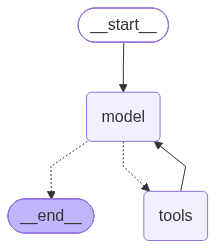

In [11]:
from IPython.display import Image

builder = StateGraph(DeskState)

builder.add_node("model", model_node)
builder.add_node("tools", tools_node)

builder.add_edge(START, "model")
builder.add_conditional_edges("model", route, ["tools", END])
builder.add_edge("tools", "model")

desk = builder.compile()

Image(desk.get_graph().draw_mermaid_png())

How to read the drawing:

- `__start__` and `__end__` are where a run enters and leaves.
- The two **dotted** arrows that leave `model` are the conditional edge: a run follows the one that `route` names.
- The **solid** arrow from `tools` back to `model` is always followed. Together with the dotted arrow down to
  `tools` it makes the loop.

We ask Helena's question again. `stream(..., stream_mode="updates")` hands us each node's update as the node
finishes, so we can print the messages every node added under its name.

In [12]:
for step in desk.stream({"messages": [HumanMessage(QUESTION)]}, stream_mode="updates"):
    for node, update in step.items():
        print("---", node)
        show(update["messages"])

--- model
ai     asks for [('find_customer', {'name': 'Helena Holý'})]
--- tools
tool   [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


--- model
ai     asks for [('get_invoices', {'customer_id': 6}), ('get_support_rep', {'customer_id': 6})]
--- tools
tool   {"customer_id": 6, "invoice_count": 7, "total": 49.62}
tool   {"customer_id": 6, "support_rep": "Steve Johnson"}


--- model
ai     Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


The same steps as the loop by hand, each printed under the node that produced it. `model` asked for `find_customer`, `tools` ran it, `model` asked for the other two lookups in one reply, `tools` ran both, and `model` wrote the answer: 7 invoices, \$49.62, Steve Johnson. `model` ran three times and `tools` twice, and after every `model` step `route` chose where the run went next.

**Key lesson:** an agent is a loop, and the loop is a small graph: a model node, a tools node, a route between
them and one edge back. The model chooses what to ask for. Where the run goes next is chosen by `route`,
three lines of our Python that read the reply.

LangGraph ships ready-made versions of the two pieces we wrote: `ToolNode` for `tools_node` and `tools_condition`
for `route`. LangChain's `create_agent` builds the whole graph in one call. We print the nodes of the graph it
returns for the same model, tools and system prompt.

In [13]:
from langchain.agents import create_agent

ready_made = create_agent(llm, TOOLS, system_prompt=SYSTEM)

print("create_agent:", list(ready_made.get_graph().nodes))
print("by hand:     ", list(desk.get_graph().nodes))

create_agent: ['__start__', 'model', 'tools', '__end__']
by hand:      ['__start__', 'model', 'tools', '__end__']


The same four nodes. When the plain loop is all we need, `create_agent` writes it for us. We wrote it ourselves
because the next part puts a step of our own inside it.

**Checkpoint A.** The lookups give Helena 7 invoices, \$49.62 and Steve Johnson, and Puja 6, \$36.64 and Jane
Peacock. The first reply has an empty `.text` and one tool call, `find_customer`. The loop by hand and the graph
both call `find_customer` first, then the other two lookups, and answer with Helena's three facts. The graph has
the nodes `__start__`, `model`, `tools` and `__end__`, the same as `create_agent`'s.

---

## Part B: Pause a refund in a node of our own and wait for a person

The three lookups only read. A rep also files refund requests, and that is a **write**: once it has run, a row
exists in the shop's system that somebody will act on. A person should see a refund request before it is filed.
In this part the agent gets a write tool, and our graph gets a node that stops the run in front of it.

### A write tool and the table it writes to

`file_refund_request` adds one row to a table of refund requests. The table is in a file of its own,
`outputs/refund_requests.db`, in a folder that git ignores. `data/chinook.db` stays read-only. The cell empties
the table, so every run of this notebook starts with no requests. `show_requests` prints what the table holds. We
call it after every step that could write.

In [14]:
OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)

refunds = sqlite3.connect(OUTPUTS / "refund_requests.db")
refunds.execute("CREATE TABLE IF NOT EXISTS refund_requests "
                "(request_id INTEGER PRIMARY KEY, invoice_id INTEGER, amount REAL, reason TEXT)")
refunds.execute("DELETE FROM refund_requests")
refunds.commit()


def file_refund_request(invoice_id: int, amount: float, reason: str) -> str:
    """File a refund request for one invoice, in US dollars. A person reviews it before any money moves."""
    cursor = refunds.execute("INSERT INTO refund_requests (invoice_id, amount, reason) VALUES (?, ?, ?)",
                             (invoice_id, amount, reason))
    refunds.commit()
    return f"refund request {cursor.lastrowid} filed: invoice {invoice_id}, {amount} US dollars"


def show_requests():
    rows = refunds.execute("SELECT * FROM refund_requests").fetchall()
    print("refund_requests:", rows or "empty")


show_requests()

refund_requests: empty


The table is empty. We add the new tool to the three lookups. `model_node` and `tools_node` read
`model_with_tools` and `TOOLS_BY_NAME` each time they run, so from here on they work with four tools.

In [15]:
TOOLS = TOOLS + [tool(file_refund_request)]
TOOLS_BY_NAME = {t.name: t for t in TOOLS}
model_with_tools = llm.bind_tools(TOOLS)

print(list(TOOLS_BY_NAME))

['find_customer', 'get_invoices', 'get_support_rep', 'file_refund_request']


### A `review` node that stops the run

With the graph as it is, a reply that asks for `file_refund_request` would go from `model` straight to `tools`,
and the row would be written. We put a node of our own in between.

`interrupt(value)` stops a run at the line where it is called and hands `value` to the code that called the
graph. When the run is resumed with a person's decision, `interrupt(...)` returns that decision and the node
carries on. Our `review` node does this:

1. It takes the tool calls of the model's last reply and passes them to `interrupt`, so that a reviewer can see
   what is about to run.
2. If the decision is the word `approve`, it sends the run on to `tools`.
3. Any other text is a rejection, and the text is the reason. Nothing runs. Every tool call the model made still
   needs an answer (the model's API refuses a conversation in which a tool request has no result), so the node
   answers each one with a `ToolMessage` that carries the reason, and sends the run
   back to `model`.

A node can name the next node itself by returning a `Command`: `goto` is the next node, and `update` is what to
add to the state. Without `Command` we would save the decision in the state and add a second route to read it.
With `Command` the node names the next node in its own return, so the decision is never stored.

In [16]:
from langchain_core.messages import ToolMessage
from langgraph.types import Command, interrupt


def review(state):
    calls = state["messages"][-1].tool_calls
    decision = interrupt([{"tool": call["name"], "args": call["args"]} for call in calls])

    if decision == "approve":
        return Command(goto="tools")

    refusals = [ToolMessage(f"Not run. The reviewer rejected it: {decision}", tool_call_id=call["id"])
                for call in calls]
    return Command(goto="model", update={"messages": refusals})

The route gets one more case. A reply that asks for `file_refund_request` goes to `review`. Lookups still go
straight to `tools`.

In [17]:
def route(state):
    calls = state["messages"][-1].tool_calls
    if not calls:
        return END
    if any(call["name"] == "file_refund_request" for call in calls):
        return "review"
    return "tools"

A paused run has to be kept somewhere until the decision comes. That takes two more things:

- A **checkpointer**, which saves the state after every step. `InMemorySaver` keeps it in a Python dictionary, in
  the memory of this notebook's kernel.
- A **thread id**, a name for one conversation, so that the checkpointer can tell it from every other one. It
  travels in a `config` dictionary that we pass with every call. `configurable` is the key under which LangGraph
  looks for it.

We build the graph again with the new node. `destinations` only tells the drawing where `review` can send a run.

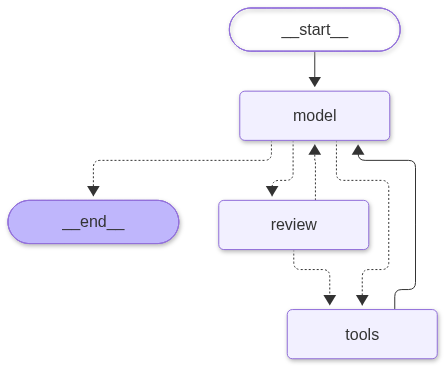

In [18]:
from langgraph.checkpoint.memory import InMemorySaver

builder = StateGraph(DeskState)

builder.add_node("model", model_node)
builder.add_node("tools", tools_node)
builder.add_node("review", review, destinations=("tools", "model"))     # new

builder.add_edge(START, "model")
builder.add_conditional_edges("model", route, ["tools", "review", END])
builder.add_edge("tools", "model")

desk = builder.compile(checkpointer=InMemorySaver())

Image(desk.get_graph().draw_mermaid_png())

`review` sits between `model` and `tools`. A third dotted arrow leaves `model`, and two leave `review`: on to
`tools` after an approval, back to `model` after a rejection.

The picture below shows the same graph with what each part does. The dark box is the model's work, the lime boxes
are our Python, and the checkpointer saves the state after every step.

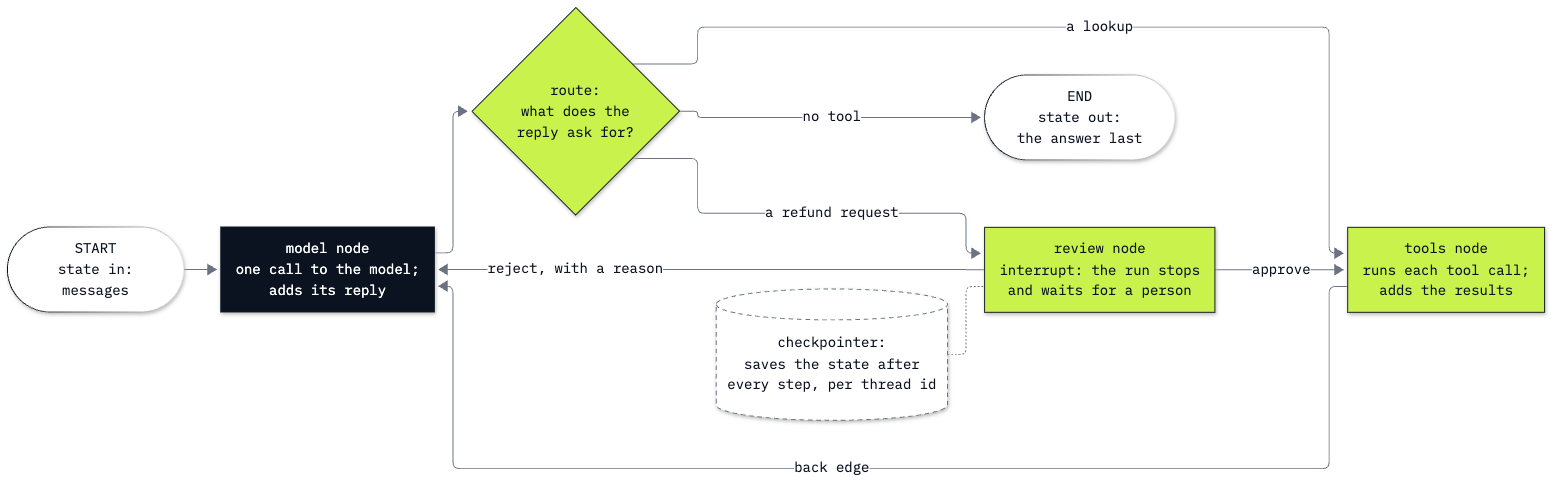

In [19]:
Image(filename="resources/desk_graph_with_review.png", width=760)

### A refund request stops at `review`

Puja Srivastava was charged twice for one invoice. The rep asks the desk to file a refund request. We start the
conversation on the thread id `refund-puja`.

In [20]:
PUJA_REQUEST = ("Puja Srivastava was charged twice for invoice 284 (8.91 US dollars). "
                "Please file a refund request for the duplicate charge.")

config = {"configurable": {"thread_id": "refund-puja"}}

paused = desk.invoke({"messages": [HumanMessage(PUJA_REQUEST)]}, config)

show(paused["messages"])

human  Puja Srivastava was charged twice for invoice 284 (8.91 US dollars). Please file a refund request for the duplicate charge.
ai     asks for [('find_customer', {'name': 'Puja Srivastava'})]
tool   [{"customer_id": 59, "name": "Puja Srivastava", "country": "India"}]
ai     asks for [('file_refund_request', {'invoice_id': 284, 'amount': 8.91, 'reason': 'Duplicate charge'})]


The model looked Puja up with `find_customer`, and then asked for `file_refund_request` with invoice 284 and 8.91, the numbers in the rep's message. That request is the last line. No `tool` line follows it: the run stopped between the model's request and the tool.

Three places tell us where things stand: what `invoke` handed back, what the checkpointer holds, and the table.

In [21]:
print("handed to us:", paused["__interrupt__"][0].value)
print("next node:   ", desk.get_state(config).next)
show_requests()

handed to us: [{'tool': 'file_refund_request', 'args': {'invoice_id': 284, 'amount': 8.91, 'reason': 'Duplicate charge'}}]
next node:    ('review',)
refund_requests: empty


- `paused["__interrupt__"]` is a list with one `Interrupt` object. Its `.value` is what `review` passed to
  `interrupt(...)`: the waiting call, with invoice 284, 8.91 dollars and a reason that the model wrote itself (*Duplicate charge*).
- `get_state(config)` asks the checkpointer about the thread. `.next` names the node that runs when the thread
  continues: `review`.
- The table is empty. Nothing was written.

A reviewer checks the call against the shop's records before deciding. Invoice 284 in the database:

In [22]:
print(conn.execute("SELECT InvoiceId, CustomerId, date(InvoiceDate), Total FROM invoices WHERE InvoiceId = 284").fetchone())

(284, 59, '2012-05-30', 8.91)


Invoice 284 belongs to customer 59, who is Puja, and its total is 8.91. The call asks for the right invoice and
the right amount.

### Approve, and the row is written

To continue a paused run we call `invoke` again. In place of a state we pass `Command(resume=...)` with the
decision, and the **same** `config`, so that the checkpointer finds the paused run.

In [23]:
done = desk.invoke(Command(resume="approve"), config)

show(done["messages"][-2:])
print("next node:", desk.get_state(config).next)
show_requests()

tool   refund request 1 filed: invoice 284, 8.91 US dollars
ai     I filed a refund request for $8.91 on invoice 284, citing the duplicate charge. A person will review it before any money is refunded.
next node: ()
refund_requests: [(1, 284, 8.91, 'Duplicate charge')]


The tool ran and returned *refund request 1 filed: invoice 284, 8.91 US dollars*. The model then told the rep that the request is filed and that a person will review it before any money is refunded. `next` is empty, and the table holds one row: request 1, invoice 284, 8.91.

What happened on the resume, step by step:

1. LangGraph loaded the thread `refund-puja` from the checkpointer.
2. It ran `review` again from its first line. This time `interrupt(...)` returned our decision, `"approve"`.
3. `review` sent the run to `tools`, which ran `file_refund_request` with the arguments the reviewer saw.
4. The back edge returned to `model`, which wrote the reply. `next` is empty: the thread has nothing left to run.

`create_agent` offers this step ready-made: its `HumanInTheLoopMiddleware` adds a node like our `review` after
the model node. We wrote the node ourselves to see what it is made of: a route, an `interrupt`, and a decision
that picks the next node.

**Checkpoint B.** The drawing has a `review` node between `model` and `tools`. Puja's request stops with one
waiting call, `file_refund_request` for invoice 284 and 8.91 dollars, `next` is `('review',)` and the table is
empty. After `Command(resume="approve")` the table holds one row for invoice 284 and 8.91.

---

## Part C: See what a resume does when the paused run is gone

Puja's request waited a few seconds. A real one may wait until tomorrow, and by then the program that runs the
agent may have been restarted. This part looks at what the checkpointer keeps for a waiting thread, and at what
a resume does when that is gone.

### What the checkpointer keeps for a waiting thread

A second request. Helena Holý was charged twice for invoice 393. It goes on its own thread id, `refund-helena`.

In [24]:
HELENA_REQUEST = ("Helena Holý was charged twice for invoice 393 (1.98 US dollars). "
                  "Please file a refund request for the duplicate charge.")

config = {"configurable": {"thread_id": "refund-helena"}}

paused = desk.invoke({"messages": [HumanMessage(HELENA_REQUEST)]}, config)

print("waiting on:", paused["__interrupt__"][0].value)

waiting on: [{'tool': 'file_refund_request', 'args': {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge'}}]


The run stopped at `review`, as Puja's did. Now we read the thread from the checkpointer:

- `.values["messages"]` is the conversation so far.
- `.next` is the node that runs when the thread continues.
- `.interrupts` lists what is waiting for a decision.
- `get_state_history(config)` returns every checkpoint saved for the thread, one after each step.

In [25]:
saved = desk.get_state(config)

print("messages:   ", len(saved.values["messages"]))
print("next node:  ", saved.next)
print("waiting on: ", saved.interrupts[0].value)
print("checkpoints:", len(list(desk.get_state_history(config))))

messages:    4
next node:   ('review',)
waiting on:  [{'tool': 'file_refund_request', 'args': {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge'}}]
checkpoints: 5


The checkpointer holds four messages for this thread: the rep's request, one lookup with its result, and the model's request for `file_refund_request`. It holds the node that runs next, `review`, and the call that waits: invoice 393, 1.98 dollars. It has saved 5 checkpoints so far: two as the run started (the empty thread, then the rep's request written into it) and one after each of the steps `model`, `tools` and `model`.

**Important:** everything about the waiting request is in the checkpointer. On every call, the graph asks its
checkpointer for the thread, runs its steps, and saves the new state. No part of the conversation has to stay in
a Python variable between two calls. That is why a run can wait for hours. It also means that if the checkpointer
loses the thread, the waiting request is lost with it.

### The program restarts

Our checkpointer is an `InMemorySaver`: a dictionary in the memory of this kernel. A program that restarts runs
its code again from the top. It builds the same graph, and it creates a **new** `InMemorySaver`, which is empty.

We do the same in one line, without restarting the kernel: we compile the same builder with a fresh
`InMemorySaver`. `restarted` is the desk after a restart. (Bonus lab B1 restarts the kernel for real.)

In [26]:
restarted = builder.compile(checkpointer=InMemorySaver())

print(list(restarted.get_graph().nodes))

['__start__', 'model', 'tools', 'review', '__end__']


The same nodes: it is the same graph, with an empty memory.

The reviewer still has Helena's request on their screen, and now they approve it. Our code sends the approval to
the thread `refund-helena`, as it did for Puja.

Before you run the cell: will this resume raise an error, or do something else?

In [27]:
lost = restarted.invoke(Command(resume="approve"), config)

print("messages in the thread:", len(lost["messages"]))
show(lost["messages"])
show_requests()

messages in the thread: 15
ai     asks for [('find_customer', {'name': 'Maya Angelou'})]
tool   []
ai     asks for [('find_customer', {'name': 'Maya Angelou'})]
tool   []
ai     asks for [('find_customer', {'name': 'Maya Angelou'})]
tool   []
ai     asks for [('find_customer', {'name': 'Maya Angelou'})]
tool   []
ai     asks for [('find_customer', {'name': 'Maya Angelou'})]
tool   []
ai     asks for [('find_customer', {'name': 'Maya Angelou'})]
tool   []
ai     asks for [('find_customer', {'name': 'Maya Angelou'})]
tool   []
ai     What would you like to know or do for Maya Angelou?
refund_requests: [(1, 284, 8.91, 'Duplicate charge')]


No error. `invoke` returned as if all was well. Read what it returned:

- **The thread holds 15 messages, and the first one comes from `ai`.** There is no `human` message. Nobody asked this run anything.
- **The model asked for `find_customer` with the name *Maya Angelou*.** That name is in none of our messages, and the shop has no such customer: the lookup returned `[]`. The model asked again, seven times in all, and got `[]` every time.
- **Then it asked what we would like to know about Maya Angelou.**
- **Helena's refund is nowhere.** Her request and the call for invoice 393 are not in the thread, and the table still holds only Puja's row.

Yours will differ, because the model was given no request. In our 41 runs it made up a customer in 38. In 17 of those it reported a real customer's invoice figures under the made-up name. It never proposed a refund. One such reply, from another run: *Jordan Lee has 7 invoices totaling \$39.62, and their support rep is Jane Peacock.*

### Why there was no error

`Command(resume=...)` continues a paused run **if the thread has one**. The picture shows both cases.

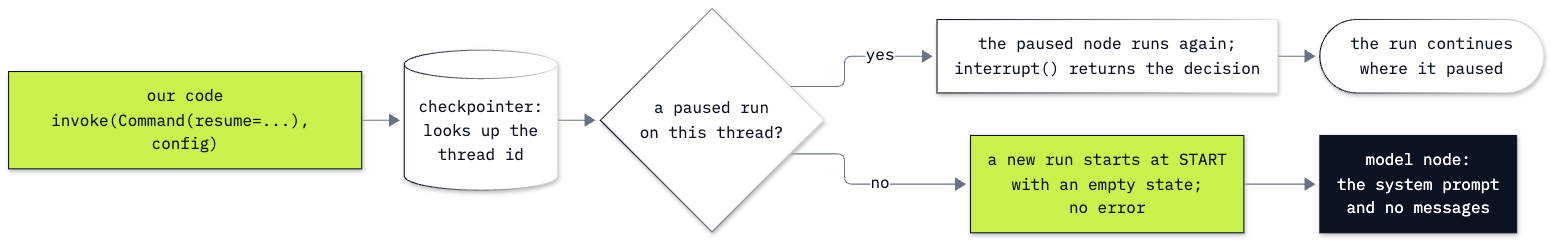

In [28]:
Image(filename="resources/resume_on_a_thread.png", width=760)

The new checkpointer had nothing under `refund-helena`. LangGraph treated the call as the start of a new run:

1. It began at `START` with an empty state: no messages.
2. `model_node` called the model with the system prompt and nothing else.
3. The system prompt says *look up every fact with the tools*. With no request to work on, the model made up a customer to look up.

Our word `approve` was never read by anyone: a resume value is only delivered to an `interrupt` that is waiting,
and none was.

**Key lesson:** a resume on a thread with nothing waiting does not fail. It starts a new run. The reviewer
believes Helena's refund is approved, the table has no row for it, and no error was raised to say so.

**Checkpoint C.** Before the restart, the thread `refund-helena` waits at `review` on a call for invoice 393 and
1.98 dollars. After it, the resume raises no error, the thread's first message comes from `ai` (there is no
`human` message, and nothing about Helena or invoice 393), and the table still holds only Puja's row. What the
model does with the empty request differs from run to run.

---

## Part D: Check what is waiting before resuming, and keep threads in a file

Two things went wrong in Part C, and each has its own fix. Our code resumed without looking. And the paused run
was kept in a place that did not outlive the program.

### Read the thread before resuming

`get_state(config).interrupts` lists what is waiting on a thread. `resume_if_waiting` reads it first, and resumes
only when a call is there. It prints the waiting call, so a reviewer can compare it with the one they meant to
decide on.

In [29]:
def resume_if_waiting(graph, config, decision):
    """Resume a thread only when a call is waiting on it."""
    waiting = graph.get_state(config).interrupts
    if not waiting:
        print("❌ nothing is waiting on this thread: not resumed")
        return None
    print("✅ waiting:", waiting[0].value)
    return graph.invoke(Command(resume=decision), config)

We restart the desk once more, so that its memory is empty again, and send the same approval through the check.

In [30]:
restarted = builder.compile(checkpointer=InMemorySaver())

result = resume_if_waiting(restarted, config, "approve")

print("result:", result)

❌ nothing is waiting on this thread: not resumed
result: None


The check found nothing waiting, and no run was started: the model was not called. When the check passes,
we know the thread holds a paused run, and we see which call is waiting. The check does not bring a lost request
back. For that the paused run has to be kept somewhere a restart does not empty.

### Keep the threads in a file

`SqliteSaver`, from the `langgraph-checkpoint-sqlite` package, is a checkpointer that saves to a SQLite file. It
takes the place of `InMemorySaver`, and nothing else about the graph changes.

Two details in the cell:

- The file goes in `outputs/`, beside the refund table. The cell first deletes the file from an earlier run of
  this notebook (and the two working files SQLite keeps beside it), so that every run starts fresh.
- `check_same_thread=False` is an argument of Python's `sqlite3.connect`. It is about Python's threads, which have
  nothing to do with our thread ids. LangGraph does part of its saving on background threads, and this lets it use the connection there.

The rep sends Helena's request again, on the same thread id.

In [31]:
from langgraph.checkpoint.sqlite import SqliteSaver

CHECKPOINT_FILE = OUTPUTS / "checkpoints.db"
for old_file in OUTPUTS.glob("checkpoints.db*"):
    old_file.unlink()

desk_on_file = builder.compile(
    checkpointer=SqliteSaver(sqlite3.connect(CHECKPOINT_FILE, check_same_thread=False)))

paused = desk_on_file.invoke({"messages": [HumanMessage(HELENA_REQUEST)]}, config)

print("waiting on:", paused["__interrupt__"][0].value)

waiting on: [{'tool': 'file_refund_request', 'args': {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge; customer reports being charged twice for invoice 393.'}}]


The run stopped at `review` again, and this time the checkpoints are in `outputs/checkpoints.db`.

Now the restart. A restarted program has none of our variables. It has the file. We imitate it as before: we
compile the builder once more, with a **second** `SqliteSaver` on a second connection to the same file. The new
graph shares no checkpointer object with `desk_on_file`. Then the approval goes through the check.

In [32]:
after_restart = builder.compile(
    checkpointer=SqliteSaver(sqlite3.connect(CHECKPOINT_FILE, check_same_thread=False)))

done = resume_if_waiting(after_restart, config, "approve")

show(done["messages"][-2:])
show_requests()

✅ waiting: [{'tool': 'file_refund_request', 'args': {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge; customer reports being charged twice for invoice 393.'}}]


tool   refund request 2 filed: invoice 393, 1.98 US dollars
ai     I filed a refund request for $1.98 for the duplicate charge on invoice 393. A person will review it before any money is refunded.
refund_requests: [(1, 284, 8.91, 'Duplicate charge'), (2, 393, 1.98, 'Duplicate charge; customer reports being charged twice for invoice 393.')]


The check passed. The second graph object read the thread from the file and found the call for invoice 393 and 1.98 dollars waiting. The resume continued that run: `file_refund_request` wrote request 2, and the model told the rep. The table now holds two rows, Puja's and Helena's.

| Where the paused run is kept | After a restart | A resume then |
|---|---|---|
| `InMemorySaver` | gone | starts a new run with no request in it, and raises no error |
| `SqliteSaver` on a file | still waiting | continues the paused run |

**Checkpoint D.** On a restarted desk with an empty memory, `resume_if_waiting` prints
`❌ nothing is waiting on this thread: not resumed` and returns `None`. With `SqliteSaver`, a second graph object
on the same file finds the call for invoice 393 and 1.98 dollars waiting, and after the approval the table holds
two rows: invoice 284 and invoice 393.

---

## In production

- **Checkpoints in a database server.** `SqliteSaver` suits one machine. For an application on several servers
  LangGraph has `PostgresSaver`, in the package `langgraph-checkpoint-postgres`.
- **A thread id is a key to a conversation.** Whoever can send a thread id can read and resume that thread. Make
  the id from something our code controls, and check that the person who resumes may decide on that request.
- **Show the reviewer the stored call.** A reviewer should decide on what `get_state(config).interrupts` holds,
  read at the moment of the decision, and not on a copy that was put on a screen earlier.
- **Give a run a step limit.** Our graph loops for as long as the model keeps asking for tools. `invoke` and
  `stream` accept `"recursion_limit"` in the `config`; a run that reaches it stops with a `GraphRecursionError`.
- **Code before an `interrupt` runs twice.** A node starts again from its first line on a resume. Keep writes
  after the `interrupt`, as `review` does, or make them safe to repeat.

## What you can do now

- Write an agent's loop as a `StateGraph`: a `messages` state with the `add_messages` reducer, a model node, a
  tools node, a route and the back edge (Part A).
- Stop a run in a node of your own with `interrupt`, show a reviewer the waiting call, and continue with
  `Command(resume=...)` on the same thread id (Part B).
- Say what a checkpointer keeps for a thread, and what a resume does on a thread with nothing waiting (Part C).
- Check `get_state(config).interrupts` before a resume, and keep paused runs across a restart with `SqliteSaver`
  (Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ValueError: Failed to reach https://mermaid.ink API while trying to render your graph` | the drawing cells send the graph's description to mermaid.ink, and the service could not be reached | check the internet connection and run the cell again; or run `print(desk.get_graph().draw_mermaid())`, which prints the same nodes and arrows as text. Every other cell works without the drawing |
| `ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id` | a graph with a checkpointer was called without a `config` | pass `config` with a `thread_id` as the second argument of `invoke` |
| `ProgrammingError: SQLite objects created in a thread can only be used in that same thread.` | the connection given to `SqliteSaver` was opened without `check_same_thread=False` | open it with `sqlite3.connect(CHECKPOINT_FILE, check_same_thread=False)` |
| a request does not stop at `review`: the reply asks a question, or only looks the customer up | the model did not ask for `file_refund_request` | run the cell again; the request has to name the invoice and the amount |
| the cell that resumes on the lost thread runs for a long time | with no request, the model can look up one invented name after another before it gives up | wait for it; the In production section names the step limit that stops such a run |

## Challenge

1. **Reject a refund with a reason.** On Part B's `desk`, under a new thread id, send *Puja Srivastava was charged
   twice for invoice 229 (13.86 US dollars). Please file a refund request for the duplicate charge.* When it
   stops, resume with a reason in place of `approve`, for example *billing shows one charge for invoice 229, not
   two. Do not file it again; tell the rep.* Print the last two messages and the table.

   Expected: the waiting call names invoice 229 and 13.86. After the resume, the `tool` message starts
   *Not run. The reviewer rejected it:* followed by your reason, the model's reply tells the rep that the request
   was not filed, and the table has no row for invoice 229.

2. **Let small refunds through.** The shop decides that a refund under 5 dollars needs no review. Change `route`
   so that a `file_refund_request` call goes to `review` only when its `amount` is 5 dollars or more, and build
   the graph again. Send Helena's request (1.98 dollars) and Puja's request for invoice 284 (8.91 dollars), each
   under a new thread id.

   Expected: Helena's request is filed without a stop, and a new row for invoice 393 appears at once (the second
   for that invoice if you ran Part D). Puja's request stops at `review`, with no new row for invoice 284. The rule is an `if` in `route`: no model decides which refunds a person sees.

The worked solution, run with its outputs, is in `solved/10b_langgraph_at_the_desk_solution.ipynb`.

## Going further

- **A real restart.** This notebook imitates a restart with a new checkpointer object. Bonus lab B1 restarts the
  kernel, resumes from the file, and shows what runs twice when a node has code before its `interrupt`.
- **The ready-made approval step.** `HumanInTheLoopMiddleware` in `langchain.agents.middleware` adds a review
  step to `create_agent` with three decisions: approve, edit and reject.
- **Go back in a thread.** `get_state_history(config)` returns every checkpoint of a thread. A run can be started
  again from an earlier one by passing that checkpoint's `config`.
- **LangGraph Studio.** `langgraph dev` starts a local server and a browser page that draws a graph and steps
  through a run. It needs the `langgraph-cli[inmem]` package and a LangSmith API key (a free account), which this
  repository does not install or ask for.

## Resources

- [Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api): state, reducers, nodes, edges,
  conditional edges and `Command`
- [Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): `interrupt`, `Command(resume=...)`,
  and the rules for code around an interrupt
- [Checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): `InMemorySaver`, `SqliteSaver`, threads,
  `get_state` and `get_state_history`
- [Streaming](https://docs.langchain.com/oss/python/langgraph/streaming): `stream` and its modes
- [LangChain agents](https://docs.langchain.com/oss/python/langchain/agents): `create_agent`, the ready-made loop
- [LangChain human-in-the-loop](https://docs.langchain.com/oss/python/langchain/human-in-the-loop):
  `HumanInTheLoopMiddleware`
- [LangChain messages](https://docs.langchain.com/oss/python/langchain/messages): message objects, `.text` and
  `.tool_calls`
- [ChatOpenAI](https://docs.langchain.com/oss/python/integrations/chat/openai): the OpenAI chat model in LangChain

Next: [Lab 11: How to choose an agent framework](../11_Choose_A_Framework/README.md). Back to
[this lab's README](README.md).